In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

con = sqlite3.connect("../data/router.db")
df = pd.read_sql("SELECT * FROM queries", con)
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print("duplicate prompts:", df.duplicated(subset="prompt").sum())
df.head()

(2415, 8)
id              int64
source            str
subject           str
prompt            str
gold_answer       str
domain            str
prompt_chars    int64
word_count      int64
dtype: object
id              0
source          0
subject         0
prompt          0
gold_answer     0
domain          0
prompt_chars    0
word_count      0
dtype: int64
duplicate prompts: 0


,id,source,subject,prompt,gold_answer,domain,prompt_chars,word_count
0,1,mmlu,econometrics,Consider the estimation of a GARCH-M model. If...,C,technical,296,54
1,2,mmlu,college_mathematics,The maximum number of acute angles in a convex...,C,technical,99,23
2,3,mmlu,electrical_engineering,The resistance of a conductor of diameter d an...,C,technical,188,43
3,4,mmlu,high_school_statistics,Which among the following would result in the ...,C,technical,236,39
4,5,mmlu,college_computer_science,One approach to handling fuzzy logic data migh...,C,technical,304,57


In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

con = sqlite3.connect("../data/router.db")
df = pd.read_sql("SELECT * FROM queries", con)
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print("duplicate prompts:", df.duplicated(subset="prompt").sum())
df.head()

(2415, 8)
id              int64
source            str
subject           str
prompt            str
gold_answer       str
domain            str
prompt_chars    int64
word_count      int64
dtype: object
id              0
source          0
subject         0
prompt          0
gold_answer     0
domain          0
prompt_chars    0
word_count      0
dtype: int64
duplicate prompts: 0


,id,source,subject,prompt,gold_answer,domain,prompt_chars,word_count
0,1,mmlu,econometrics,Consider the estimation of a GARCH-M model. If...,C,technical,296,54
1,2,mmlu,college_mathematics,The maximum number of acute angles in a convex...,C,technical,99,23
2,3,mmlu,electrical_engineering,The resistance of a conductor of diameter d an...,C,technical,188,43
3,4,mmlu,high_school_statistics,Which among the following would result in the ...,C,technical,236,39
4,5,mmlu,college_computer_science,One approach to handling fuzzy logic data migh...,C,technical,304,57


In [3]:
print(pd.read_sql("""SELECT source, COUNT(*) AS n,
               ROUND(AVG(prompt_chars)) AS avg_chars,
               MAX(prompt_chars) AS max_chars
               FROM queries GROUP BY source""", con))
pd.read_sql("""SELECT domain, COUNT(*) AS n,
               ROUND(AVG(prompt_chars)) AS avg_chars
               FROM queries GROUP BY domain ORDER BY n DESC""", con)

   source    n  avg_chars  max_chars
0     arc  800      264.0        903
1  custom   15      133.0        244
2   gsm8k  800      241.0        848
3    mmlu  800      321.0       1126


,domain,n,avg_chars
0,general,1600,253.0
1,technical,400,335.0
2,business,400,306.0
3,programming,6,91.0
4,data_analytics,4,120.0
5,finance_ops,3,175.0
6,it_helpdesk,2,222.0


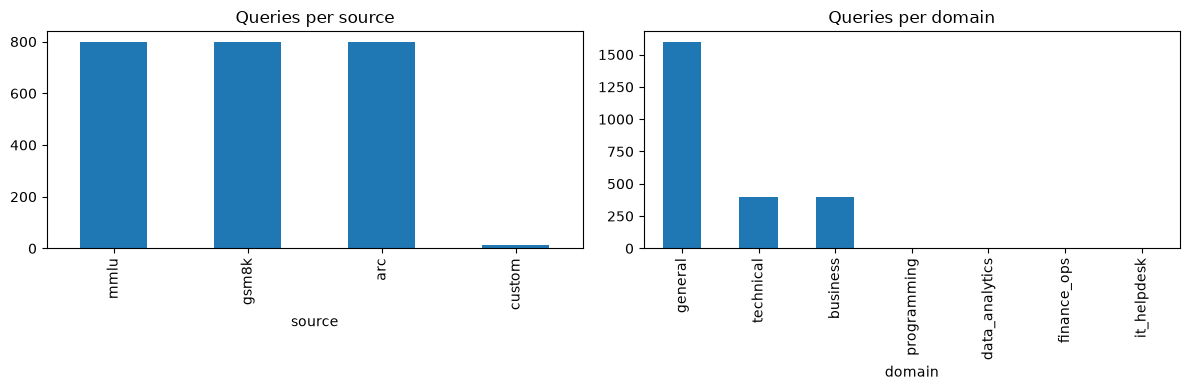

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["source"].value_counts().plot.bar(ax=ax[0], title="Queries per source")
df["domain"].value_counts().plot.bar(ax=ax[1], title="Queries per domain")
plt.tight_layout()
plt.savefig("../reports/figures/eda_overview.png", dpi=150)
plt.show()

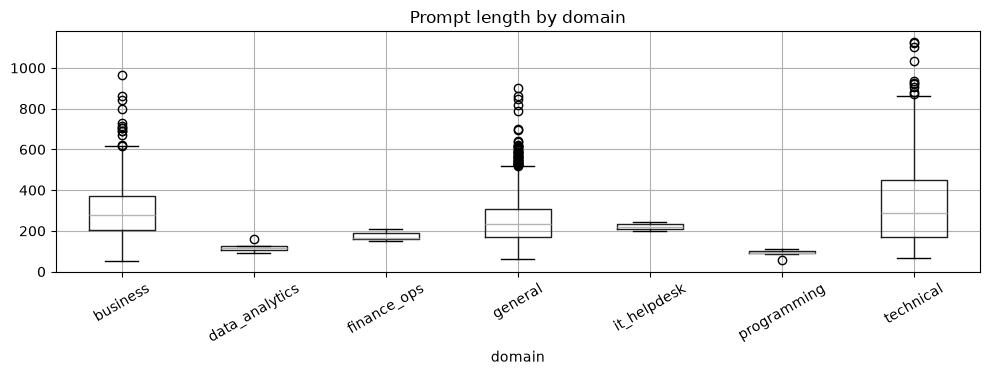

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
df.boxplot(column="prompt_chars", by="domain", ax=ax, rot=30)
ax.set_title("Prompt length by domain")
plt.suptitle("")
plt.tight_layout()
plt.savefig("../reports/figures/length_by_domain.png", dpi=150)
plt.show()

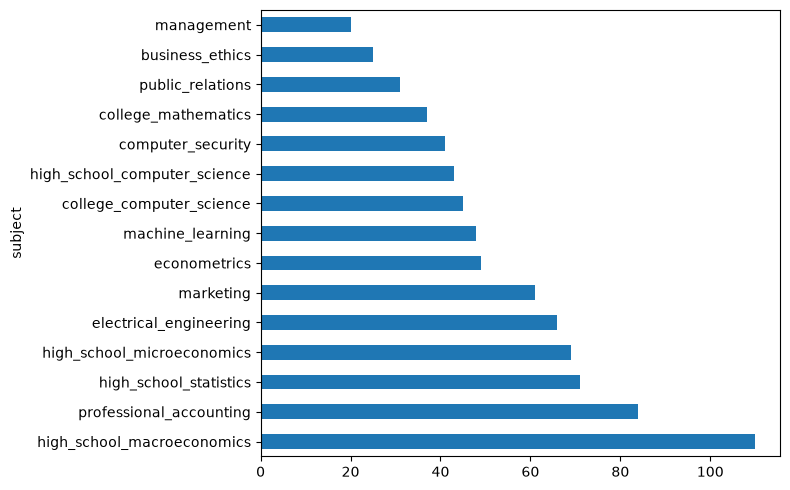

In [6]:
df[df.source == "mmlu"]["subject"].value_counts().plot.barh(figsize=(8, 5))
plt.tight_layout()
plt.savefig("../reports/figures/mmlu_subjects.png", dpi=150)
plt.show()

In [7]:
mc = df[df.source != "gsm8k"]
print(pd.crosstab(mc["source"], mc["gold_answer"], normalize="index").round(2))

gsm = df[df.source == "gsm8k"]
print("non-numeric GSM8K answers:", pd.to_numeric(gsm["gold_answer"], errors="coerce").isna().sum())

gold_answer     A     B     C     D
source                             
arc          0.23  0.26  0.26  0.25
custom       0.27  0.20  0.27  0.27
mmlu         0.23  0.24  0.25  0.28
non-numeric GSM8K answers: 0


In [ ]:
#Takeaways
1. **Balanced sources, uneven domains.** MMLU, GSM8K, and ARC contribute 800 questions each, but the `general` domain (GSM8K + ARC) is 1,600 of 2,415 rows, while the four custom domains total only 15 rows.
2. **Technical and business questions are the longest.** Average prompt length is about 335 characters for technical and 306 for business, versus 253 for general, with outliers near 1,100 characters. Longer prompts cost more tokens, which matters for the cost analysis.
3. **Custom questions are much shorter** (about 90-220 characters), so prompt length alone could reveal the source. I will add longer scenario-style questions so length does not become a shortcut for the router.
4. **MMLU subjects are uneven.** Macroeconomics (about 110) and professional accounting (about 84) dominate, while management (about 20) and business ethics (about 25) are small, so per-subject results for small subjects will be noisy.
5. **Labels are clean.** Correct-answer letters are balanced at about 25% each in ARC and MMLU, and all GSM8K answers are numeric, so exact-match grading is safe.
6. **Next step:** grow the custom set to about 150 questions.

SyntaxError: invalid syntax (3509597690.py, line 2)